# P3.04 — IMI and IMT revenue

**Question:** RQ7.1 (how have IMI and IMT revenues evolved?). Groundwork for RQ7.2 (what a rate cut costs).

No machine-readable municipal revenue exists (`docs/data_quality.md`), so this is national: general-government revenue from
taxes on land and buildings (IMI) and from taxes on financial and capital transactions (IMT with stamp duty) in the national
accounts, 1995 to 2025, on an accrual basis. IMI revenue is a rate times an assessed base that follows tax values, not market
prices. IMT revenue applies a rate schedule to the value of homes sold, so it follows prices and the number of sales. The rate
is observed from 2012 (`at_imi_rates`, weighted by the 2021 stock of dwellings); the base is revenue over rate, so it carries
everything else: reassessments, exemptions, the additional IMI (AIMI) on high-value property and accrual timing.

In [1]:
import pandas as pd

from pthousing.analysis import revenue
from pthousing.config import PROCESSED
from pthousing.data import interim
from pthousing.viz import charts, style

style.apply_style()
panel = pd.read_parquet(PROCESSED / "panel_municipality_year.parquet")
long = pd.read_parquet(PROCESSED / "national_annual_long.parquet")
rate = revenue.weighted_imi_rate(panel)
a = revenue.annual_frame(interim.read("eurostat_property_tax"), interim.read("ine_cpi"), long, rate)
print(
    f"{a.index.min()}-{a.index.max()}, {len(a)} years; rate observed {rate.index.min()}-{rate.index.max()}"
)

1995-2025, 31 years; rate observed 2012-2025


## Step 1 — Revenue over thirty years
Real revenue in euros of the base year, and both taxes next to the real house price index (2015 = 100).

,imi_real_eur_m,imt_real_eur_m,imi_gdp_pct,imt_gdp_pct,hpi_real_b2015
year,,,,,
1995,592.98,550.13,0.35,0.32,121.72
2000,838.13,1107.10,0.40,0.52,138.06
2007,1346.14,1294.76,0.58,0.55,126.70
2013,1635.46,429.55,0.79,0.21,93.27
2015,1867.38,685.55,0.86,0.32,100.00
2019,2006.36,1190.33,0.80,0.48,137.28
2022,1757.69,1772.43,0.67,0.68,168.52
2025,1764.38,2050.88,0.59,0.68,213.87


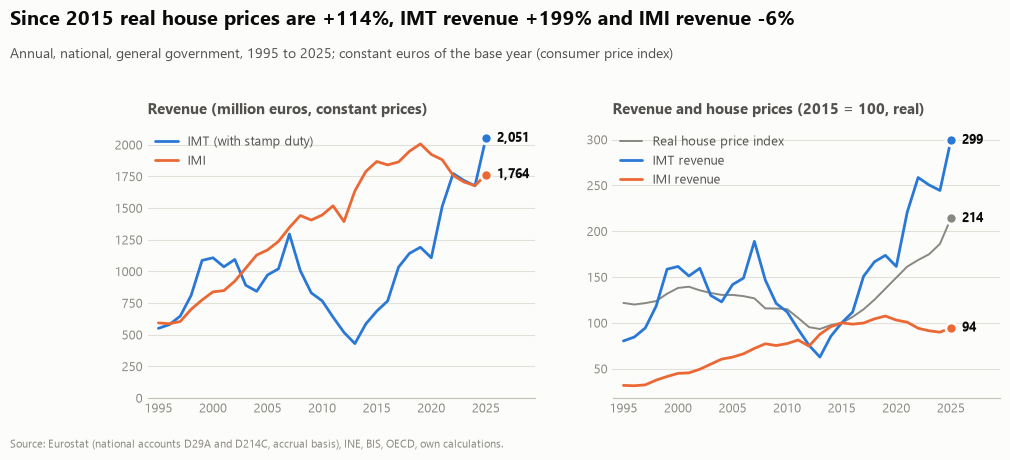

In [2]:
fig = charts.property_tax_revenue(a)
style.save_fig(fig, "p3", "property_tax_revenue")
years = [1995, 2000, 2007, 2013, 2015, 2019, 2022, 2025]
levels = a.loc[
    years, ["imi_real_eur_m", "imt_real_eur_m", "imi_gdp_pct", "imt_gdp_pct", "hpi_real_b2015"]
]
style.save_table(levels.round(2).reset_index(), "p3", "property_tax_levels")
series = a[
    ["imi_real_eur_m", "imt_real_eur_m", "imi_real_b2015", "imt_real_b2015", "hpi_real_b2015"]
]
style.save_table(
    series.round(2).reset_index(), "p3", "property_tax_series"
)  # every year, for the dashboard
levels.round(2)

## Step 2 — Episodes
Percentage changes over the boom, the crisis and the recovery. IMT moves with the market (it fell by two thirds in real terms
from 2007 to 2013 and has since passed its earlier peak); IMI did not fall in the crisis (it rose, the base was being reassessed:
the general reassessment of urban buildings ran in 2011-2013, not modelled here) and has lagged prices since.

In [3]:
windows = {
    "1995-2007 boom": (1995, 2007),
    "2007-2013 crisis": (2007, 2013),
    "2013-2019 recovery": (2013, 2019),
    "2019-2025 price surge": (2019, 2025),
    "2013-2025": (2013, 2025),
}
cols = [
    "imi_eur_m",
    "imi_real_eur_m",
    "imt_eur_m",
    "imt_real_eur_m",
    "hpi_nominal_b2015",
    "hpi_real_b2015",
]
episodes = revenue.changes(a, windows, cols)
style.save_table(episodes.round(1).reset_index(), "p3", "property_tax_episodes")
episodes.round(1)

,imi_eur_m,imi_real_eur_m,imt_eur_m,imt_real_eur_m,hpi_nominal_b2015,hpi_real_b2015
window,,,,,,
1995-2007 boom,219.1,127.0,230.9,135.4,46.3,4.1
2007-2013 crisis,33.9,21.5,-63.4,-66.8,-18.9,-26.4
2013-2019 recovery,27.0,22.7,187.0,177.1,52.4,47.2
2019-2025 price surge,5.0,-12.1,105.7,72.3,86.0,55.8
2013-2025,33.4,7.9,490.2,377.4,183.4,129.3


## Step 3 — IMI: rate and base
The weighted average rate fell from 2012 as councils cut and more sat at the 0.3% floor. The rest of the change in revenue is
the base. Compared with the nominal house price, the gap shows how far the base lags the market: assessed values are revised
on sale, on renewal and in general reassessments, not with the market.

In [4]:
windows_imi = {"2013-2019": (2013, 2019), "2019-2025": (2019, 2025), "2013-2025": (2013, 2025)}
parts = pd.DataFrame(
    {k: revenue.decompose_imi(a, *w) for k, w in windows_imi.items()}
).T.rename_axis("window")
style.save_table(parts.round(1).reset_index(), "p3", "imi_decomposition")
print("log points; base = revenue - rate; gap = base - nominal house price")
parts.round(1)

log points; base = revenue - rate; gap = base - nominal house price


,revenue,rate,base,price,gap
window,,,,,
2013-2019,23.9,-7.3,31.3,42.1,-10.9
2019-2025,4.9,-5.0,9.8,62.0,-52.2
2013-2025,28.8,-12.3,41.1,104.2,-63.1


In [5]:
rate_path = a.loc[2012:, ["imi_rate_pct", "imi_eur_m", "imi_base_b2015", "hpi_nominal_b2015"]]
style.save_table(rate_path.round(3).reset_index(), "p3", "imi_rate_and_base")
rate_path.round(3)

,imi_rate_pct,imi_eur_m,imi_base_b2015,hpi_nominal_b2015
year,,,,
2012,0.374,1150.1,72.901,94.862
2013,0.370,1353.9,86.914,93.081
2014,0.371,1476.4,94.475,97.039
2015,0.367,1549.1,100.000,100.000
2016,0.356,1536.1,102.501,107.110
2017,0.351,1577.0,106.504,117.011
2018,0.347,1664.9,113.822,129.028
2019,0.343,1720.1,118.834,141.877
2020,0.335,1648.6,116.593,154.310


## Step 4 — Does this match the simulator's anchors?
`config/scenarios.yaml` carries hand-entered 2024 anchors from press and the tax authority (IMI assessed 1,630 EUR m; IMT collected
1,732.8 EUR m). The national accounts are a different measure (accrual, not assessed or cash), so only the scale is compared.

In [6]:
anchors = {"imi_eur_m": 1630.0, "imt_eur_m": 1732.8}
check = pd.DataFrame(
    {
        "national_accounts_2024": [a.loc[2024, c] for c in anchors],
        "simulator_anchor_2024": list(anchors.values()),
    },
    index=list(anchors),
)
check["difference_pct"] = 100 * (
    check["national_accounts_2024"] / check["simulator_anchor_2024"] - 1
)
style.save_table(check.round(1).reset_index(names="tax"), "p3", "property_tax_anchor_check")
check.round(1)

,national_accounts_2024,simulator_anchor_2024,difference_pct
imi_eur_m,1677.2,1630.0,2.9
imt_eur_m,1675.4,1732.8,-3.3


## Key numbers

In [7]:
e, p = episodes, parts
print(
    f"IMT: real {e.loc['2007-2013 crisis', 'imt_real_eur_m']:+.0f}% in 2007-2013, {e.loc['2013-2025', 'imt_real_eur_m']:+.0f}% in 2013-2025; "
    f"2025 {a.loc[2025, 'imt_real_eur_m']:,.0f} EUR m ({a.loc[2025, 'imt_gdp_pct']:.2f}% of GDP) against {a.loc[2007, 'imt_real_eur_m']:,.0f} in 2007 ({a.loc[2007, 'imt_gdp_pct']:.2f}%)"
)
print(
    f"IMI: real {e.loc['2013-2019 recovery', 'imi_real_eur_m']:+.0f}% in 2013-2019, {e.loc['2019-2025 price surge', 'imi_real_eur_m']:+.0f}% in 2019-2025; "
    f"share of GDP {a['imi_gdp_pct'].max():.2f}% ({a['imi_gdp_pct'].idxmax()}) -> {a.loc[2025, 'imi_gdp_pct']:.2f}% (2025)"
)
print(
    f"2013-2025 IMI in log points: revenue {p.loc['2013-2025', 'revenue']:+.0f} = rate {p.loc['2013-2025', 'rate']:+.0f} + base {p.loc['2013-2025', 'base']:+.0f}; "
    f"nominal house price {p.loc['2013-2025', 'price']:+.0f}, so the base lags it by {-p.loc['2013-2025', 'gap']:.0f}"
)
print(
    f"2019-2025: rate {p.loc['2019-2025', 'rate']:+.0f}, base {p.loc['2019-2025', 'base']:+.0f}, price {p.loc['2019-2025', 'price']:+.0f}"
)
print(
    f"rate {rate.loc[2012]:.3f}% (2012) -> {rate.loc[2025]:.3f}% (2025); a 0.01 pp cut of the average rate ~ "
    f"{a.loc[2025, 'imi_eur_m'] * 0.01 / rate.loc[2025]:.0f} EUR m of 2025 revenue (linear, nominal)"
)
print(check.round(1).to_string())

IMT: real -67% in 2007-2013, +377% in 2013-2025; 2025 2,051 EUR m (0.68% of GDP) against 1,295 in 2007 (0.55%)
IMI: real +23% in 2013-2019, -12% in 2019-2025; share of GDP 0.86% (2015) -> 0.59% (2025)
2013-2025 IMI in log points: revenue +29 = rate -12 + base +41; nominal house price +104, so the base lags it by 63
2019-2025: rate -5, base +10, price +62
rate 0.374% (2012) -> 0.327% (2025); a 0.01 pp cut of the average rate ~ 55 EUR m of 2025 revenue (linear, nominal)
           national_accounts_2024  simulator_anchor_2024  difference_pct
imi_eur_m                  1677.2                 1630.0             2.9
imt_eur_m                  1675.4                 1732.8            -3.3
